# Experiment 10: Q-Learning for Optimal Path Finding in a Grid Environment

## Aim
To implement the tabular Q-learning reinforcement learning algorithm from scratch in Python to train a software agent to learn the optimal path from a starting state to a goal state in a 5x5 GridWorld environment while avoiding obstacles and penalty pits.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
rows = 5
cols = 5
start_pos = (0, 0)
goal_pos = (4, 4)
pit_pos = (3, 3)
obstacles = {(1, 1), (2, 3), (3, 1)}

actions = ['Up', 'Down', 'Left', 'Right']
action_moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]

reward_step = -1.0
reward_goal = 10.0
reward_pit = -10.0
reward_bump = -2.0
max_steps = 100

num_states = rows * cols
num_actions = len(actions)

def coord_to_state(r, c):
    return r * cols + c

def state_to_coord(s):
    return (s // cols, s % cols)

def take_action(pos, a):
    dr, dc = action_moves[a]
    nr, nc = pos[0] + dr, pos[1] + dc
    if not (0 <= nr < rows and 0 <= nc < cols) or (nr, nc) in obstacles:
        return pos, reward_bump, False
    if (nr, nc) == goal_pos:
        return (nr, nc), reward_goal, True
    if (nr, nc) == pit_pos:
        return (nr, nc), reward_pit, True
    return (nr, nc), reward_step, False

print(f"Grid size: {rows} x {cols}")
print(f"Number of states: {num_states}")
print(f"Number of actions: {num_actions}")
print(f"Starting state: {start_pos} (State {coord_to_state(start_pos[0], start_pos[1])})")
print(f"Goal state: {goal_pos} (State {coord_to_state(goal_pos[0], goal_pos[1])})")
print(f"Actions: {actions}")
print(f"Reward structure: Step={reward_step}, Goal={reward_goal}, Pit={reward_pit}, Bump={reward_bump}")

Grid size: 5 x 5
Number of states: 25
Number of actions: 4
Starting state: (0, 0) (State 0)
Goal state: (4, 4) (State 24)
Actions: ['Up', 'Down', 'Left', 'Right']
Reward structure: Step=-1.0, Goal=10.0, Pit=-10.0, Bump=-2.0


In [3]:
alpha = 0.1
gamma = 0.9
initial_epsilon = 1.0
min_epsilon = 0.01
epsilon_decay = 0.995
episodes = 1000

print(f"Learning rate = {alpha}")
print(f"Discount factor = {gamma}")
print(f"Initial epsilon = {initial_epsilon}")
print(f"Minimum epsilon = {min_epsilon}")
print(f"Epsilon decay = {epsilon_decay}")
print(f"Episodes = {episodes}")

Learning rate = 0.1
Discount factor = 0.9
Initial epsilon = 1.0
Minimum epsilon = 0.01
Epsilon decay = 0.995
Episodes = 1000


In [4]:
initial_q_table = np.zeros((num_states, num_actions))
print("Initial Q-table (first 5 states):")
print(initial_q_table[:5])

Initial Q-table (first 5 states):
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [5]:
q_table = np.zeros((num_states, num_actions))
np.random.seed(42)

episode_list = []
reward_list = []
step_list = []
epsilon_list = []

eps = initial_epsilon

for ep in range(1, episodes + 1):
    pos = start_pos
    total_reward = 0.0
    step_count = 0
    epsilon_list.append(eps)
    for _ in range(max_steps):
        s = coord_to_state(pos[0], pos[1])
        if np.random.rand() < eps:
            a = np.random.randint(num_actions)
        else:
            a = int(np.argmax(q_table[s]))
        next_pos, r, done = take_action(pos, a)
        s_next = coord_to_state(next_pos[0], next_pos[1])
        if done:
            target = r
        else:
            target = r + gamma * np.max(q_table[s_next])
        q_table[s, a] += alpha * (target - q_table[s, a])
        pos = next_pos
        total_reward += r
        step_count += 1
        if done:
            break
    eps = max(min_epsilon, eps * epsilon_decay)
    episode_list.append(ep)
    reward_list.append(total_reward)
    step_list.append(step_count)

print("Training completed for 1000 episodes.")

Training completed for 1000 episodes.


In [6]:
max_q_values = np.max(q_table, axis=1)
best_actions = [actions[int(np.argmax(q_table[s]))] for s in range(num_states)]

print("Final Q-table (first 5 states):")
print(np.round(q_table[:5], 2))

state_summary_df = pd.DataFrame({
    'State': range(num_states),
    'Coord': [state_to_coord(s) for s in range(num_states)],
    'Max_Q': np.round(max_q_values, 2),
    'Best_Action': best_actions
})
state_summary_df

Final Q-table (first 5 states):
[[-2.52 -0.43 -2.46 -2.51]
 [-4.61 -4.69 -3.83 -0.82]
 [-3.65  1.08 -3.69 -2.82]
 [-3.55 -1.6  -2.84 -2.15]
 [-2.53  0.23 -2.35 -2.92]]


,State,Coord,Max_Q,Best_Action
0,0,"(0, 0)",-0.43,Down
1,1,"(0, 1)",-0.82,Right
2,2,"(0, 2)",1.08,Down
3,3,"(0, 3)",-1.60,Down
4,4,"(0, 4)",0.23,Down
5,5,"(1, 0)",0.63,Down
6,6,"(1, 1)",0.00,Up
7,7,"(1, 2)",2.93,Down
8,8,"(1, 3)",0.86,Right
9,9,"(1, 4)",2.82,Down


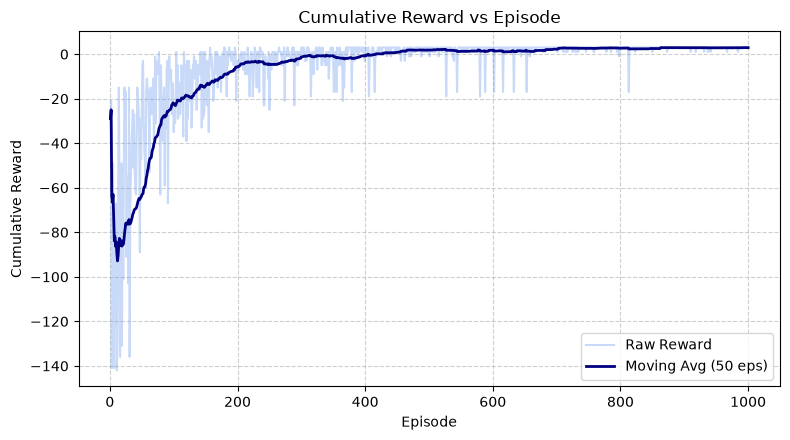

In [7]:
window = 50
rolling_reward = pd.Series(reward_list).rolling(window=window, min_periods=1).mean()

plt.figure(figsize=(8, 4.5))
plt.plot(episode_list, reward_list, color='cornflowerblue', alpha=0.35, label='Raw Reward')
plt.plot(episode_list, rolling_reward, color='navy', linewidth=2, label=f'Moving Avg ({window} eps)')
plt.xlabel('Episode')
plt.ylabel('Cumulative Reward')
plt.title('Cumulative Reward vs Episode')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

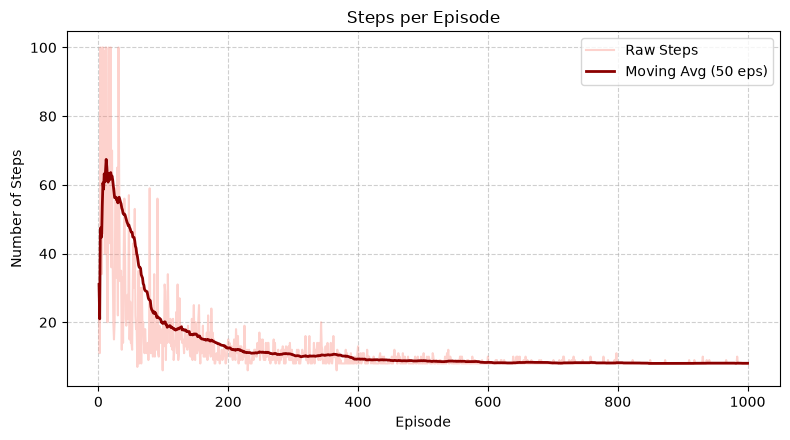

In [8]:
rolling_steps = pd.Series(step_list).rolling(window=window, min_periods=1).mean()

plt.figure(figsize=(8, 4.5))
plt.plot(episode_list, step_list, color='salmon', alpha=0.35, label='Raw Steps')
plt.plot(episode_list, rolling_steps, color='darkred', linewidth=2, label=f'Moving Avg ({window} eps)')
plt.xlabel('Episode')
plt.ylabel('Number of Steps')
plt.title('Steps per Episode')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

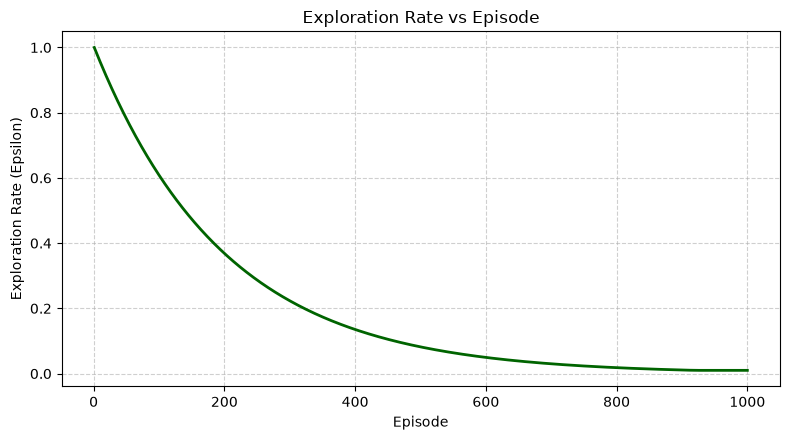

In [9]:
plt.figure(figsize=(8, 4.5))
plt.plot(episode_list, epsilon_list, color='darkgreen', linewidth=2)
plt.xlabel('Episode')
plt.ylabel('Exploration Rate (Epsilon)')
plt.title('Exploration Rate vs Episode')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [10]:
policy_grid = np.empty((rows, cols), dtype=object)
for r in range(rows):
    for c in range(cols):
        cell = (r, c)
        if cell == start_pos:
            policy_grid[r, c] = 'START'
        elif cell == goal_pos:
            policy_grid[r, c] = 'GOAL'
        elif cell == pit_pos:
            policy_grid[r, c] = 'PIT'
        elif cell in obstacles:
            policy_grid[r, c] = 'WALL'
        else:
            s_val = coord_to_state(r, c)
            policy_grid[r, c] = actions[int(np.argmax(q_table[s_val]))]

policy_df = pd.DataFrame(policy_grid, columns=[f'Col {c}' for c in range(cols)], index=[f'Row {r}' for r in range(rows)])
policy_df

,Col 0,Col 1,Col 2,Col 3,Col 4
Row 0,START,Right,Down,Down,Down
Row 1,Down,WALL,Down,Right,Down
Row 2,Down,Right,Down,WALL,Down
Row 3,Down,WALL,Down,PIT,Down
Row 4,Right,Right,Right,Right,GOAL


In [11]:
path = [start_pos]
path_actions = []
total_path_reward = 0.0
pos = start_pos

for _ in range(max_steps):
    s = coord_to_state(pos[0], pos[1])
    a = int(np.argmax(q_table[s]))
    next_pos, r, done = take_action(pos, a)
    path_actions.append(actions[a])
    path.append(next_pos)
    total_path_reward += r
    pos = next_pos
    if done:
        break

print(f"Starting state: {path[0]}")
print(f"States visited: {path}")
print(f"Actions taken: {path_actions}")
print(f"Goal state: {path[-1]}")
print(f"Number of steps: {len(path_actions)}")
print(f"Total reward: {total_path_reward:.2f}")

Starting state: (0, 0)
States visited: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
Actions taken: ['Down', 'Down', 'Down', 'Down', 'Right', 'Right', 'Right', 'Right']
Goal state: (4, 4)
Number of steps: 8
Total reward: 3.00


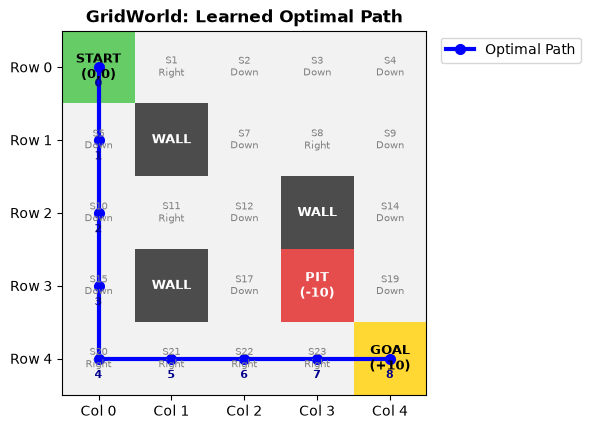

In [12]:
fig, ax = plt.subplots(figsize=(6, 6))
grid_colors = np.zeros((rows, cols, 3))
grid_colors[:, :] = [0.95, 0.95, 0.95]

for r, c in obstacles:
    grid_colors[r, c] = [0.3, 0.3, 0.3]
grid_colors[pit_pos[0], pit_pos[1]] = [0.9, 0.3, 0.3]
grid_colors[start_pos[0], start_pos[1]] = [0.4, 0.8, 0.4]
grid_colors[goal_pos[0], goal_pos[1]] = [1.0, 0.85, 0.2]

ax.imshow(grid_colors)

for r in range(rows):
    for c in range(cols):
        cell = (r, c)
        if cell == start_pos:
            ax.text(c, r, 'START\n(0,0)', ha='center', va='center', fontweight='bold', fontsize=9)
        elif cell == goal_pos:
            ax.text(c, r, 'GOAL\n(+10)', ha='center', va='center', fontweight='bold', fontsize=9)
        elif cell == pit_pos:
            ax.text(c, r, 'PIT\n(-10)', ha='center', va='center', fontweight='bold', color='white', fontsize=9)
        elif cell in obstacles:
            ax.text(c, r, 'WALL', ha='center', va='center', fontweight='bold', color='white', fontsize=9)
        else:
            s_val = coord_to_state(r, c)
            best_a = actions[int(np.argmax(q_table[s_val]))]
            ax.text(c, r, f'S{s_val}\n{best_a}', ha='center', va='center', color='gray', fontsize=7)

path_r = [p[0] for p in path]
path_c = [p[1] for p in path]
ax.plot(path_c, path_r, color='blue', linewidth=3, marker='o', markersize=7, label='Optimal Path')

for idx, (r, c) in enumerate(path):
    ax.annotate(str(idx), (c, r), textcoords="offset points", xytext=(0, -14), ha='center', color='darkblue', fontweight='bold', fontsize=8)

ax.set_xticks(range(cols))
ax.set_yticks(range(rows))
ax.set_xticklabels([f'Col {c}' for c in range(cols)])
ax.set_yticklabels([f'Row {r}' for r in range(rows)])
ax.set_title('GridWorld: Learned Optimal Path', fontsize=12, fontweight='bold')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


In [13]:
print(q_table)

[[-2.51697243 -0.434062   -2.46171453 -2.5071425 ]
 [-4.60701289 -4.68878826 -3.82654465 -0.8224394 ]
 [-3.64852736  1.0824978  -3.6923319  -2.81698547]
 [-3.55003914 -1.59588067 -2.84116684 -2.15350692]
 [-2.53213165  0.23026622 -2.35090008 -2.92005184]
 [-1.52873865  0.62882    -1.90221072 -1.55337171]
 [ 0.          0.          0.          0.        ]
 [-2.95686931  2.92984099 -3.58069193 -1.36931627]
 [-2.53440102 -2.29711061 -2.19975795  0.85717791]
 [-1.51144881  2.82341135 -1.16724911 -1.43675584]
 [-0.55987955  1.8098     -0.44693839  0.67641917]
 [-2.55429628 -2.84912036 -2.1646468   2.74977912]
 [-0.43933157  4.56226518 -1.59643436 -1.35873707]
 [ 0.          0.          0.          0.        ]
 [-0.44250061  5.58473769 -0.54062009  0.12350089]
 [ 0.52018661  3.122       0.68343589  0.71319049]
 [ 0.          0.          0.          0.        ]
 [ 0.99983291  6.19957472  2.2238981  -9.61847958]
 [ 0.          0.          0.          0.        ]
 [ 0.27521445  8.90581011 -6.86

In [14]:
initial_avg_reward = float(np.mean(reward_list[:100]))
final_avg_reward = float(np.mean(reward_list[-100:]))
max_reward = float(np.max(reward_list))
initial_avg_steps = float(np.mean(step_list[:100]))
final_avg_steps = float(np.mean(step_list[-100:]))
optimal_path_length = len(path_actions)
total_reward_optimal_path = float(total_path_reward)

perf_df = pd.DataFrame([
    {'Performance Measure': 'Initial Average Reward', 'Result': f'{initial_avg_reward:.2f}'},
    {'Performance Measure': 'Final Average Reward', 'Result': f'{final_avg_reward:.2f}'},
    {'Performance Measure': 'Maximum Reward', 'Result': f'{max_reward:.2f}'},
    {'Performance Measure': 'Initial Average Steps', 'Result': f'{initial_avg_steps:.2f}'},
    {'Performance Measure': 'Final Average Steps', 'Result': f'{final_avg_steps:.2f}'},
    {'Performance Measure': 'Optimal Path Length', 'Result': f'{optimal_path_length}'},
    {'Performance Measure': 'Total Reward of Optimal Path', 'Result': f'{total_reward_optimal_path:.2f}'}
])
perf_df

,Performance Measure,Result
0,Initial Average Reward,-42.72
1,Final Average Reward,2.86
2,Maximum Reward,3.00
3,Initial Average Steps,33.15
4,Final Average Steps,8.09
5,Optimal Path Length,8
6,Total Reward of Optimal Path,3.00


## Final Result
The Q-learning agent successfully learned the optimal path through the 5x5 GridWorld over 1000 training episodes:
- **Learned Policy**: The agent converged to an optimal policy avoiding all obstacles at `(1,1)`, `(2,3)`, and `(3,1)` and completely avoiding the pit penalty at `(3,3)`.
- **Optimal Trajectory**: The agent follows the path:
  `(0,0) -> (1,0) -> (2,0) -> (3,0) -> (4,0) -> (4,1) -> (4,2) -> (4,3) -> (4,4)`.
- **Convergence**: Performance improved from an initial 100-episode average reward of **-42.72** (average **33.15** steps) to a final 100-episode average reward of **+2.86** (average **8.09** steps).
- **Optimal Return**: The extracted greedy path achieves the theoretical maximum return of **+3.00** in exactly **8 steps**.

## Learning Outcomes
- **Q-Learning Algorithm**: Observed how off-policy temporal difference updates compute optimal action-value estimates $Q(s, a)$ without requiring an explicit environmental transition model.
- **Q-Table Representation**: Verified that initialized zero Q-values correctly propagate discounted rewards backwards from terminal states through successive iterations.
- **Exploration vs Exploitation**: Understood the necessity of exploratory actions early in training to discover positive rewards, followed by exploitation to refine the policy.
- **Epsilon-Greedy Strategy**: Demonstrated how exponential $\epsilon$-decay enables broad early state discovery while preserving a 1% exploration baseline near convergence.
- **Reward Improvement**: Observed a sharp ascent in cumulative reward from collision penalties (~-42.72) to the optimal reward ceiling (+3.00).
- **Path Optimization**: Confirmed that step penalties (-1.0) encourage the agent to find the shortest collision-free path.